## Introducción

Este cuaderno realiza un **barrido paramétrico** sobre la razón $D_1/D_2$ en el modelo de dos regiones en coordenada desplazada $z'$, donde $D_1$ es la difusividad en la zona superficial $[0, z_c]$ y $D_2 = 2\times10^3\,\text{nm}^2/\mu\text{s}$ es la difusividad bulk fija. Se barren cuatro valores: $D_1/D_2 \in \{0.001,\, 0.01,\, 0.1,\, 1.0\}$.

Para cada valor de $D_1/D_2$ se recalcula la difusividad efectiva armónica $D_\text{eff}$, se recomputan los autovalores axiales $\Lambda_{nm}^2$ en paralelo (joblib, 4 núcleos) y se evalúa $G(t)$ por suma espectral. Parámetros fijos: $d = 15\,\text{nm}$, $R = L = 50d = 750\,\text{nm}$, $z_c = 0.75 R/d$, $\kappa = 0$.

El caso $D_1/D_2 = 1$ corresponde al sistema homogéneo (sin efecto de superficie), mientras que $D_1/D_2 \ll 1$ representa una capa superficial con movilidad muy restringida.

In [1]:
import os
import numpy as np
from scipy.special import jv
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.sparse import diags
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from scipy.linalg import eigh_tridiagonal
from joblib import Parallel, delayed
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# -----------------------------------------------------------------------------
# 0. Crear carpeta para archivos temporales (si no existe)
# -----------------------------------------------------------------------------
if not os.path.isdir("data/temp_G_tworegion_z'_D"):
    os.makedirs("data/temp_G_tworegion_z'_D")

In [3]:
# -----------------------------------------------------------------------------
# 1. Parámetros físicos (en nm y unidades compatibles)
# -----------------------------------------------------------------------------
d = 15               # nm Profundidad de NV
D2 = 2e3             # nm²/us (región volumétrica)
L = R = 50*d        # nm (altura total), nm (radio del cilindro)
varkappa = 0.0       # nm/us
z_c = 2.5*d             # 37.5 nm (antes 0.75/d*L, adimensional)
n_modes_radial = 100  # Número de modos radiales
m_max = 100           # Número de modos axiales por modo radial
N_z = N_r = 15000    # Número de nodos en z y rho

In [4]:
# -----------------------------------------------------------------------------
# 2. Cálculo de D_eff (promedio armónico), que también se usa en tau = t * D_eff / d^2
# -----------------------------------------------------------------------------
def D_eff_tworegion(D1, D2, z_c, L):
    L1, L2 = z_c, L - z_c
    return (L1 + L2) / (L1/D1 + L2/D2)

In [5]:
# -----------------------------------------------------------------------------
# 3. Definición de funciones compartidas:
#    - robin_eq(alpha): ecuación trascendental radial con parámetro varkappa
#    - R_func(alpha_array, rho_array): calcula los modos radiales J0(alpha_n * rho) normalizados
#    - build_system(n): ensambla y diagonaliza la parte axial para un modo radial n
# -----------------------------------------------------------------------------
def robin_eq(alpha, varkappa, D_eff):
    """
    Ecuación trascendental radial para hallar raíces alpha_n:
       alpha * J1(alpha*R) - (varkappa / D_eff) * J0(alpha*R) = 0.
    """
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

def find_alpha_roots(varkappa, D_eff, n_roots=n_modes_radial, step=1e-4):
    """
    Encuentra las primeras `n_roots` raíces alpha_n de robin_eq(alpha)=0
    en intervalos [0, ...] usando brentq y un paso `step`.
    """
    alpha_roots = []
    alpha_current = 0.0
    while len(alpha_roots) < n_roots:
        try:
            root = brentq(lambda a: robin_eq(a, varkappa, D_eff),
                          alpha_current, alpha_current + step, xtol=1e-6)
            alpha_roots.append(root)
            alpha_current = root + step
        except ValueError:
            alpha_current += step
    return np.array(alpha_roots)

def R_func(alpha_arr, rho_arr):
    """
    Calcula los modos radiales normalizados R_n(rho) = J0(alpha_n * rho)/sqrt(norm_n).
    Retorna:
      - R_normed: array con forma (n_modes_radial, len(rho_arr))
      - norms: vector con las normas (no se usa más adelante, pero lo dejamos para consistencia)
    """
    # alpha_arr: (n_modes_radial,)
    # rho_arr: (N_rhos,)
    alpha = alpha_arr.reshape(-1, 1)   # forma (n_modes_radial, 1)
    rho = rho_arr.reshape(1, -1)       # forma (1, N_rhos)
    R_matrix = jv(0, alpha * rho)      # (n_modes_radial, N_rhos)

    # Cálculo de normas analíticas: norms[n] = sqrt{ \int_0^R rho J0^2(alpha_n rho) d rho }
    J0R = jv(0, alpha_arr * R)  # (n_modes_radial,)
    J1R = jv(1, alpha_arr * R)  # (n_modes_radial,)
    norms = 0.5 * R ** 2 * (J0R**2 + J1R**2)  # (n_modes_radial,)
    norms = np.atleast_1d(norms)
    Nnorm = 1.0 / np.sqrt(norms)  # factor de normalización

    R_normed = Nnorm[:, None] * R_matrix  # (n_modes_radial, N_rhos)
    return R_normed, np.sqrt(norms)

# --------------------------------------------------------------------------
# Nucleo del problema axial de dos regiones, con las DOS ramas.
#
# En cada region, -D Z'' + alpha^2 D Z = Lambda^2 Z  =>  Z'' = -k_i^2 Z con
# k_i^2 = (Lambda^2 - alpha^2 D_i)/D_i. La solucion es TRIGONOMETRICA si
# k_i^2 > 0 y HIPERBOLICA si k_i^2 < 0. El espectro esta acotado por abajo por
# alpha^2*min(D) = alpha^2 D1, de modo que en la banda
# alpha^2 D1 <= Lambda^2 < alpha^2 D2 la region 2 es evanescente: son los modos
# localizados en la capa superficial lenta, los mas lentos del problema y los
# que dominan la cola de G(t).
#
# La version anterior aplicaba np.abs() a ambas betas (rama equivocada) y solo
# buscaba raices desde Lambda = alpha*sqrt(D2), dejando esa banda entera fuera.
# --------------------------------------------------------------------------

def _tr_fv(alpha, k, kap, D1_, D2_, z_c_, N=20001):
    """Autovalores Lambda^2 por volumen finito, con D constante a trozos.

    Sirve solo para LOCALIZAR el espectro: devuelve todos los autovalores en
    orden y sin saltarse ninguno. Cada valor se pule despues con brentq sobre
    la ecuacion trascendental, de modo que la raiz final es la analitica.
    """
    zg = np.unique(np.concatenate([np.linspace(0.0, L, N), [z_c_]]))
    N = len(zg)
    h = np.diff(zg)
    Dv = np.where(zg < z_c_ - 1e-12, D1_,
                  np.where(zg > z_c_ + 1e-12, D2_, 2*D1_*D2_/(D1_ + D2_)))
    w = np.empty(N); w[1:-1] = 0.5*(h[:-1] + h[1:]); w[0] = h[0]/2; w[-1] = h[-1]/2
    Dh = 2*Dv[:-1]*Dv[1:]/(Dv[:-1] + Dv[1:])
    off = -Dh/h
    dia = np.zeros(N)
    dia[1:-1] = Dh[:-1]/h[:-1] + Dh[1:]/h[1:]
    dia[0]  = Dh[0]/h[0] + kap          # Robin en la superficie
    dia[-1] = Dh[-1]/h[-1]              # Neumann arriba
    dia += alpha**2 * Dv * w
    s = 1.0/np.sqrt(w)
    return eigh_tridiagonal(dia*s*s, off*s[:-1]*s[1:],
                            select='i', select_range=(0, k-1), eigvals_only=True)


def _tr_region1(zeta, Lam2, alpha, kap, D1_, z_c_):
    """0 <= zeta <= z_c, con D1 Z'(0) = kap Z(0). Devuelve (Z, Z(z_c), Z'(z_c))."""
    a1 = (Lam2 - alpha**2 * D1_) / D1_
    if a1 > 0:
        k = np.sqrt(a1)
        cc, sc = np.cos(k * z_c_), np.sin(k * z_c_)
        return (np.cos(k * zeta) + (kap / (D1_ * k)) * np.sin(k * zeta),
                cc + (kap / (D1_ * k)) * sc, -k * sc + (kap / D1_) * cc)
    if a1 == 0:
        return (1.0 + (kap / D1_) * zeta, 1.0 + (kap / D1_) * z_c_, kap / D1_)
    q = np.sqrt(-a1)
    cc, sc = np.cosh(q * z_c_), np.sinh(q * z_c_)
    return (np.cosh(q * zeta) + (kap / (D1_ * q)) * np.sinh(q * zeta),
            cc + (kap / (D1_ * q)) * sc, q * sc + (kap / D1_) * cc)


def _tr_region2(zeta, Lam2, alpha, D2_, z_c_):
    """z_c <= zeta <= L, con Z'(L) = 0. Devuelve (g, g(z_c), g'(z_c)) escalada a O(1)."""
    a2 = (Lam2 - alpha**2 * D2_) / D2_
    u, uc = zeta - L, z_c_ - L
    if a2 > 0:
        k = np.sqrt(a2)
        return np.cos(k * u), np.cos(k * uc), -k * np.sin(k * uc)
    if a2 == 0:
        return np.ones_like(np.asarray(zeta, dtype=float)), 1.0, 0.0
    q = np.sqrt(-a2)
    ref = np.cosh(q * (L - z_c_))          # evita desbordes
    return np.cosh(q * u) / ref, np.cosh(q * uc) / ref, q * np.sinh(q * uc) / ref


def _tr_match(Lam2, alpha, kap, D1_, D2_, z_c_):
    """Continuidad de Z y del flujo D Z' en zeta = z_c."""
    _, Zc, dZc = _tr_region1(0.0, Lam2, alpha, kap, D1_, z_c_)
    _, gc, dgc = _tr_region2(0.0, Lam2, alpha, D2_, z_c_)
    return D1_ * dZc * gc - D2_ * dgc * Zc


def _tr_roots(alpha, kap, D1_, D2_, z_c_, k):
    """Raices Lambda^2 del problema axial de dos regiones.

    El espectro se localiza con una diagonalizacion en volumen finito, que
    devuelve todos los autovalores en orden, y cada valor se pule con brentq
    sobre la ecuacion trascendental. Un barrido por cambio de signo no sirve:
    se salta los pares casi degenerados de las dos familias de modos, en los
    que F cruza dos veces dentro del mismo paso.
    """
    aprox = _tr_fv(alpha, k, kap, D1_, D2_, z_c_)
    lo = alpha**2 * D1_
    out = np.empty(k)
    for _i, _lam in enumerate(aprox):
        _lam = max(_lam, lo)
        _dm = _lam - aprox[_i-1] if _i > 0 else (aprox[1] - aprox[0] if k > 1 else _lam)
        _dp = aprox[_i+1] - _lam if _i + 1 < k else _dm
        _w = 0.35*max(min(abs(_dm), abs(_dp)), 1e-9) + 1e-9
        _raiz = _lam
        for _fac in (1.0, 3.0, 9.0):
            _a, _b = max(_lam - _fac*_w, lo), _lam + _fac*_w
            _fa = _tr_match(_a, alpha, kap, D1_, D2_, z_c_)
            _fb = _tr_match(_b, alpha, kap, D1_, D2_, z_c_)
            if np.isfinite(_fa) and np.isfinite(_fb) and _fa*_fb < 0:
                _raiz = brentq(_tr_match, _a, _b, args=(alpha, kap, D1_, D2_, z_c_,), xtol=1e-13, rtol=8.9e-16)
                break
        out[_i] = _raiz
    if alpha == 0.0 and kap == 0.0:
        out[0] = 0.0      # modo uniforme
    return out


def _tr_Z(zeta, Lam2, alpha, kap, D1_, D2_, z_c_):
    """Autofuncion axial sin normalizar, en la coordenada local zeta in [0, L]."""
    zeta = np.asarray(zeta, dtype=float)
    Z1, Zc, dZc = _tr_region1(zeta, Lam2, alpha, kap, D1_, z_c_)
    g, gc, dgc = _tr_region2(zeta, Lam2, alpha, D2_, z_c_)
    if abs(gc) >= abs(dgc) * (L - z_c_):
        A = Zc / gc
    else:
        A = D1_ * dZc / (D2_ * dgc)
    return np.where(zeta <= z_c_, Z1, A * g)

def transcendental_eq(Lambda, alpha_n, kappa, z_c, D1, D2):
    """Continuidad de Z y del flujo D Z' en la interfaz.

    OJO: el primer argumento es ahora Lambda^2 (el autovalor), no Lambda.
    """
    return _tr_match(Lambda, alpha_n, kappa, D1, D2, z_c)

def find_lambda_roots(alpha, kappa, z_c, D1, D2, m_roots=m_max, step=1e-2):
    """Raices Lambda^2 del problema axial de dos regiones.

    El barrido arranca en alpha^2*D1, la cota inferior real del espectro
    (antes empezaba en alpha*sqrt(D2) y se perdian los modos superficiales).
    El argumento `step` se conserva por compatibilidad y ya no se usa: el
    paso se elige a partir de alpha^2*D2.
    """
    return _tr_roots(alpha, kappa, D1, D2, z_c, m_roots)

def fz_raw(z_val, z_c, D1, D2, kappa, alpha_n, eigenvalues_ax, n, m):
    """Autofuncion axial sin normalizar (coordenada z' con origen en la superficie)."""
    return _tr_Z(z_val, eigenvalues_ax[n][m], alpha_n[n], kappa, D1, D2, z_c)

def T(t, lam):
    return np.exp(-np.abs(lam) * t)

def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return S.T # np.maximum(S.T, 0)

In [6]:
# -----------------------------------------------------------------------------
# 4. Valores de varkappa a barrer (en nm/s)
# -----------------------------------------------------------------------------
D_fraction_list = [0.001, 0.01, 0.1, 1]

In [7]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de J0(alpha_n * rho) y demás datos independientes
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
# N_quad = 1000
# rho_nodes = np.linspace(0.0, R, N_quad)  # np.linspace(0,R,N_quad)
# z_nodes = np.linspace(0.0, L, N_quad)   # en [d, L+d]
# rho0 = 0.0
# z0 = 0.0
# dr = rho_nodes[1] - rho_nodes[0]
# dz = z_nodes[1] - z_nodes[0]

# # 5.2 Construcción de la red J0(alpha_n * rho) se hará DENTRO del bucle,
# #     porque alpha_n depende de varkappa.

# # 5.3 Construcción de Z_tens (modos axiales ante nodos z_nodes) se hará DENTRO del bucle,
# #     ya que los autovectores axiales dependen de varkappa.

# # 5.4 Matriz f_mat (factor dipolar) es independiente de varkappa:
# R2 = rho_nodes**2
# Z2 = (z_nodes+d + 1e-30)**2   # pequeño desplazamiento para evitar división por cero
# f_mat = (3 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # forma (N_quad, N_quad)
# f0_mat = (3*(z0+d)**2-rho0**2)/(rho0**2+(z0+d)**2)**2.5
# rho_factor = (rho_nodes[:, None] * f0_mat * f_mat * dr * dz)

# # 5.5 Vector de tiempos t en los que se evaluará G(t)
# t_values = np.logspace(-3, 4, N_quad)   # forma (N_quad,)

In [8]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de f(ρ,z') y medida ρ dρ dz' (independientes de D1)
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z' para G(t):
# Malla de cuadratura para las integrales modales F_nm.
# El integrando esta muy concentrado cerca de la superficie: f decae como z^-3 y
# los modos axiales tienen capa limite ahi. Con malla uniforme y suma rectangular
# (dr*dz*sum) la suma modal (5/16pi) sum F_nm^2 llegaba a superar a la integral
# directa (5/16pi) int f^2 rho drho dz, imposible para Parseval truncada.
# Se agrupan nodos en la superficie con la misma transformacion sinh de la malla
# axial y se usan pesos del trapecio.
N_quad = 2000
_s = np.arange(N_quad) / (N_quad - 1)
rho_nodes = np.linspace(0.0, R, N_quad)
z_nodes   = L * np.sinh(3.0 * _s) / np.sinh(3.0)        # [0, L] = z', apretada en z'=0
def pesos_trapecio(x):
    """Pesos de la regla del trapecio para una malla posiblemente no uniforme."""
    h = np.diff(x)
    w = np.empty_like(x)
    w[1:-1] = 0.5 * (h[:-1] + h[1:])
    w[0]    = 0.5 * h[0]
    w[-1]   = 0.5 * h[-1]
    return w


w_rho = pesos_trapecio(rho_nodes)
w_z   = pesos_trapecio(z_nodes)


# 5.2 Factor dipolar f(ρ,z') en la malla (Nr, Nz)
#     Distancia al NV: z' + d
R2 = rho_nodes**2
# z_nodes es z' (0 en la superficie); la distancia al NV es z' + d
Z2 = (z_nodes + d)**2
# Kernel dipolar: f = (3cos^2(theta) - 1)/r^3 con cos(theta)=z/r, r^2=rho^2+z^2,
# es decir f = (3z^2 - r^2)/r^5 = (2z^2 - rho^2)/(rho^2+z^2)^{5/2}.
# (Antes: 3z^2 - rho^2; la resta va contra r^2, no contra rho^2. El prefactor
#  5/(16 pi) es [ (1/4)sqrt(5/pi) ]^2, el coeficiente de Y_2^0 al cuadrado.)
f_mat = (2 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # shape (Nr, Nz)

# 5.3 Medida cilíndrica ρ dρ dz'
# medida rho drho dz con pesos del trapecio en ambas direcciones
measure = (rho_nodes * w_rho)[:, None]    # shape (Nr, 1)

# 5.4 Matriz F(ρ,z') = ρ dρ dz' f(ρ,z')
F = measure * f_mat * w_z[None, :]                       # shape (Nr, Nz)

# 5.5 Vector de tiempos t en los que se evaluará G(t)
t_values = np.logspace(-3, 4, N_quad)     # (N_quad,)

In [9]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada D1/D2, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
D_eff_list = []

for f in D_fraction_list:
    print(f"--- Calculando G(t) para D1/D2 = {f} ---")
    D1 = f * D2

    # 6.1. Difusividad efectiva del modelo de dos regiones
    D_eff = D_eff_tworegion(D1, D2, z_c, L)
    D_eff_list.append(D_eff)

    # 6.2. Hallar raíces alpha_n (n_modes_radial valores) para la parte radial
    alpha_n = find_alpha_roots(varkappa, D_eff, n_roots=n_modes_radial, step=1e-4)

    # 6.3. Modos radiales normalizados en nodos rho
    R0_mat, _ = R_func(alpha_n, rho_nodes)  # shape (n_modes_radial, N_quad)

    # 6.4. Autovalores axiales λ_{n,m}(D1)
    eigenvalues_ax = Parallel(n_jobs=4, verbose=1)(
        delayed(find_lambda_roots)(alpha, varkappa, z_c, D1, D2,
                                   m_roots=m_max, step=1e-2)
        for n, alpha in enumerate(alpha_n)
    )
    eigenvalues_ax = np.array(eigenvalues_ax)   # shape (n_modes_radial, m_max)

    # 6.5. Normalizar modos axiales en z' para cada (n,m)
    C_norm = np.zeros((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_vals = fz_raw(z_nodes, z_c, D1, D2, varkappa, alpha_n, eigenvalues_ax, n, m)
            integral = np.trapezoid(Z_vals**2, z_nodes)
            C_norm[n, m] = 1.0 / np.sqrt(integral + 1e-30)

    def fz(z_val, z_c, D1, D2, kappa, alpha_n, eigenvalues_ax, n, m):
        return C_norm[n, m] * fz_raw(z_val, z_c, D1, D2, kappa, alpha_n, eigenvalues_ax, n, m)

    # 6.6. Construir Z_tens[j, n, m] = Z_{n,m}(z_nodes[j])
    Z_tens = np.empty((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_tens[:, n, m] = fz(z_nodes, z_c, D1, D2, varkappa, alpha_n, eigenvalues_ax, n, m)

    # -------------------------------------------------------------------------
    # 6.7. Coeficientes de proyección de f sobre los modos: Cproj_{n,m}(D1)
    #      Cproj_nm = ∫ ρ dρ dz' f(ρ,z') R_n(ρ) Z_{n,m}(z';D1)
    #      → Discretizado con F(ρ,z') = ρ dρ dz' f(ρ,z')
    # -------------------------------------------------------------------------
    Cproj_nm = np.zeros((n_modes_radial, m_max))

    for n in range(n_modes_radial):
        # g_n(z_k) = ∑_i R_n(ρ_i) F(ρ_i, z_k)
        g_n = np.dot(R0_mat[n, :], F)   # shape (N_quad,)
        for m in range(m_max):
            # Cproj_nm[n,m] = ∑_k g_n(z_k) Z_{n,m}(z_k)
            Cproj_nm[n, m] = np.dot(g_n, Z_tens[:, n, m])

    # -------------------------------------------------------------------------
    # 6.8. Cálculo de G(t; D1) con la suma espectral:
    #      G(t) = (5 / 16π) * ∑_{n,m} Cproj_nm^2 e^{-λ_{nm} t}
    # -------------------------------------------------------------------------
    G_values = np.zeros_like(t_values)
    for i, t_val in enumerate(t_values):
        T_decay = T(t_val, eigenvalues_ax)          # shape (n_modes_radial, m_max)
        G_values[i] = (5.0 / (16.0 * np.pi)) * np.sum((Cproj_nm**2) * T_decay)

    # -----------------------------------------------------------------------------
    # 6.9. Guardar G_values en un archivo temporal y liberar memoria
    # -----------------------------------------------------------------------------
    temp_filename = os.path.join("data/temp_G_tworegion_z'_D", f"G_D1_{int(f*D2)}.dat")
    data_to_save  = np.column_stack([t_values, G_values])  # (N_quad, 2)
    header_str    = "Tiempo(s)   G_D1{}".format(f*D2)

    np.savetxt(
        temp_filename,
        data_to_save,
        header=header_str,
        fmt="%.9e",
        comments=''
    )

    del G_values
    del data_to_save

    print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")


--- Calculando G(t) para D1/D2 = 0.001 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    9.7s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:   18.4s finished


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_2.dat' y liberado G_values.

--- Calculando G(t) para D1/D2 = 0.01 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    6.3s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:   15.5s finished


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_20.dat' y liberado G_values.

--- Calculando G(t) para D1/D2 = 0.1 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    6.3s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:   14.7s finished


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_200.dat' y liberado G_values.

--- Calculando G(t) para D1/D2 = 1 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    6.3s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:   14.4s finished


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_2000.dat' y liberado G_values.



In [10]:
# --------------------------------------------------------
# 7. Al terminar el bucle, combinamos todos los archivos temporales
# --------------------------------------------------------
print("→ Combinando archivos temporales en 'VariateD1_G_vs_t_tworegion_z'.dat' ...")

primero = True
lista_Gcols = []

for f in D_fraction_list:
    temp_filename = os.path.join("data/temp_G_tworegion_z'_D", f"G_D1_{int(f*D2)}.dat")
    # Ahora le decimos a loadtxt que omita la cabecera (1 línea)
    arr = np.loadtxt(temp_filename, skiprows=1)   # forma (N_quad, 2)

    if primero:
        t_col = arr[:, 0]   # extraemos el vector de tiempos
        primero = False
    G_col = arr[:, 1]       # extraemos la columna G(t) para este kappa
    lista_Gcols.append(G_col)

# Después seguimos exactamente igual:
G_stack = np.vstack(lista_Gcols).T               # (N_quad, 8)
output_data = np.column_stack([t_col, G_stack])  # (N_quad, 1 + 8)

header_cols = ['Tiempo(s)'] + [f'G_D1{int(f*D2)}' for f in D_fraction_list]
header_str = '   '.join(header_cols)

np.savetxt(
    "data/VariateD1_G_vs_t_tworegion_z'.dat",
    output_data,
    header=header_str,
    fmt="%.9e",
    comments=''
)

print("→ Archivo final 'VariateD1_G_vs_t_tworegion_z'.dat' creado con columnas:")
print("   ", header_cols)

→ Combinando archivos temporales en 'VariateD1_G_vs_t_tworegion_z'.dat' ...
→ Archivo final 'VariateD1_G_vs_t_tworegion_z'.dat' creado con columnas:
    ['Tiempo(s)', 'G_D12', 'G_D120', 'G_D1200', 'G_D12000']


In [11]:
df = pd.read_csv("data/VariateD1_G_vs_t_tworegion_z'.dat",sep=r'\s+',comment='#')

In [12]:
tau_values=t_values*D_eff_list[3]/d**2

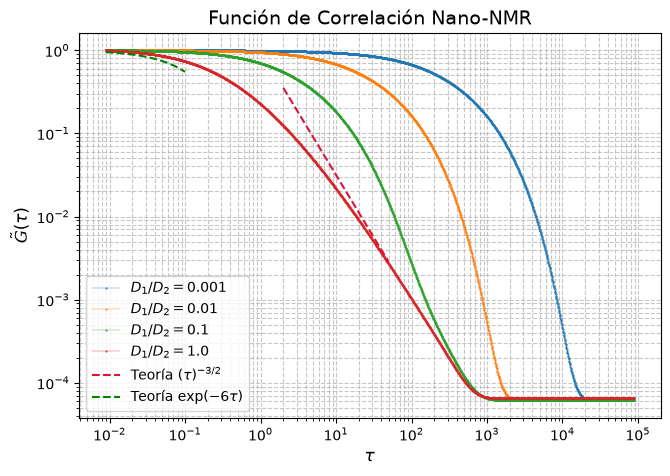

In [13]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, df.G_D12/df.G_D12[0], "o-", label=r"$D_1/D_2=0.001$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_D120/df.G_D120[0], "o-", label=r"$D_1/D_2=0.01$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_D1200/df.G_D1200[0], "o-", label=r"$D_1/D_2=0.1$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_D12000/df.G_D12000[0], "o-", label=r"$D_1/D_2=1.0$", markersize=0.5, linewidth=0.25)
plt.plot(tau_values[(tau_values>=2)&(tau_values<=50)], tau_values[(tau_values>=2)&(tau_values<=50)]**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values[(tau_values<=0.1)], np.exp(-6*tau_values[(tau_values<=0.1)]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_tworegion_z'_D1Variation.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

## Conclusiones

El barrido sobre la razón $D_1/D_2$ en el modelo de dos regiones muestra claramente cómo la reducción de difusividad en la capa superficial modifica $\tilde{G}(\tau)$:

- Para $D_1/D_2 = 1$ (sin efecto de superficie), $G(t)$ sigue el comportamiento homogéneo universal ($\exp(-6\tau)$ → $\tau^{-3/2}$).
- Al reducir $D_1/D_2$, la función de correlación se vuelve más lenta a tiempos intermedios: las moléculas en la capa de baja difusividad contribuyen a la señal durante más tiempo.
- La escala temporal adimensional $\tau = D_\text{eff}\, t / d^2$ se desplaza al variar $D_\text{eff}$ con la razón $D_1/D_2$, modificando el punto de cruce entre los dos regímenes asintóticos.

Este análisis permite cuantificar la sensibilidad de la señal Nano-NMR a la razón de difusividades entre la capa superficial y el bulk, parámetro clave para interpretar experimentos de espectroscopía en interfaces.